### Data Loading:

First, let us laod the relevant data files, and assign the results to dataframes. We might also need to assign names to columns.

In [1]:
import pandas as pd
import chardet
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_df = pd.read_csv("../data/raw/ml-100k/u.data", sep="\t", header=None)
data_df.head()
data_df.columns = ["user_id", "item_id", "rating", "timestamp"]
data_df.head()
data_df.shape

(100000, 4)

In [3]:
data_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype
---  ------     --------------   -----
 0   user_id    100000 non-null  int64
 1   item_id    100000 non-null  int64
 2   rating     100000 non-null  int64
 3   timestamp  100000 non-null  int64
dtypes: int64(4)
memory usage: 3.1 MB


In [4]:
data_df.describe()

,user_id,item_id,rating,timestamp
count,100000.00000,100000.000000,100000.000000,1.000000e+05
mean,462.48475,425.530130,3.529860,8.835289e+08
std,266.61442,330.798356,1.125674,5.343856e+06
min,1.00000,1.000000,1.000000,8.747247e+08
25%,254.00000,175.000000,3.000000,8.794487e+08
50%,447.00000,322.000000,4.000000,8.828269e+08
75%,682.00000,631.000000,4.000000,8.882600e+08
max,943.00000,1682.000000,5.000000,8.932866e+08


The file u.item contains information about the movies. timestamp can be converted to a datetime object if needed.

In [5]:
# Step 2: Read CSV File in Binary Mode
with open('../data/raw/ml-100k/u.item', 'rb') as f:
    data = f.read()

# Step 3: Detect Encoding using chardet Library
encoding_result = chardet.detect(data)

# Step 4: Retrieve Encoding Information
encoding = encoding_result['encoding']

# Step 5: Print Detected Encoding Information
print(encoding)

# This is the right method to get a file's encoding

ISO-8859-1


In [6]:
item_df = pd.read_csv("../data/raw/ml-100k/u.item", sep = "|", encoding="ISO-8859-1", header=None)
item_df.head()
item_df.columns = ["movie_id", "movie_title", "release_date", "video_release_date",
              "IMDb_URL", "unknown", "Action", "Adventure", "Animation",
              "Childrens" , "Comedy" , "Crime" , "Documentary" , "Drama" , "Fantasy",
              "Film-Noir" , "Horror" , "Musical" , "Mystery" , "Romance" , "Sci-Fi",
              "Thriller" , "War" , "Western"]
item_df.head()
item_df.info()
item_df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   movie_id            1682 non-null   int64  
 1   movie_title         1682 non-null   object 
 2   release_date        1681 non-null   object 
 3   video_release_date  0 non-null      float64
 4   IMDb_URL            1679 non-null   object 
 5   unknown             1682 non-null   int64  
 6   Action              1682 non-null   int64  
 7   Adventure           1682 non-null   int64  
 8   Animation           1682 non-null   int64  
 9   Childrens           1682 non-null   int64  
 10  Comedy              1682 non-null   int64  
 11  Crime               1682 non-null   int64  
 12  Documentary         1682 non-null   int64  
 13  Drama               1682 non-null   int64  
 14  Fantasy             1682 non-null   int64  
 15  Film-Noir           1682 non-null   int64  
 16  Horror

(1682, 24)

In [7]:
item_df["video_release_date"]

0      NaN
1      NaN
2      NaN
3      NaN
4      NaN
        ..
1677   NaN
1678   NaN
1679   NaN
1680   NaN
1681   NaN
Name: video_release_date, Length: 1682, dtype: float64

Most of the columns in the item_df dataframe are filled. The video_release_date column has no values. It can be deleted. release_date column has 1 missing value, IMDb_URL column has 3.


The release dates can be converted to datetime objects if needed. The genre columns have values entered as 0/1. Applying .mean() to these columns will automatically give us the percentage of films that belong to that genre.

For now, the column names are the same as the ones given in the README file that came with the dataset. Spaces in column names were replaced by _, and an ' was removed from the Children's column. It was named Childrens.

chardet was installed and used to find the file type of u.item file since it did not open with default settings (utf-8). Need to add that to requirements.txt file.

We delete the video_release_date column.

In [8]:
del item_df["video_release_date"]
item_df.info()
item_df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1682 entries, 0 to 1681
Data columns (total 23 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   movie_id      1682 non-null   int64 
 1   movie_title   1682 non-null   object
 2   release_date  1681 non-null   object
 3   IMDb_URL      1679 non-null   object
 4   unknown       1682 non-null   int64 
 5   Action        1682 non-null   int64 
 6   Adventure     1682 non-null   int64 
 7   Animation     1682 non-null   int64 
 8   Childrens     1682 non-null   int64 
 9   Comedy        1682 non-null   int64 
 10  Crime         1682 non-null   int64 
 11  Documentary   1682 non-null   int64 
 12  Drama         1682 non-null   int64 
 13  Fantasy       1682 non-null   int64 
 14  Film-Noir     1682 non-null   int64 
 15  Horror        1682 non-null   int64 
 16  Musical       1682 non-null   int64 
 17  Mystery       1682 non-null   int64 
 18  Romance       1682 non-null   int64 
 19  Sci-Fi

(1682, 23)

We add the column release_year to item_df. This is to track whether the release year affect a movie's rating.

Let us create a pandas series containing the release year of each film. Later, we can categorize the years using pd.cut() if required.

In [9]:
release_year = item_df.release_date.str[-4:]
release_year.shape
release_year = release_year.fillna("1995") # Fill in missing values with the median
release_year = release_year.astype("int")
release_year
release_year.describe()
release_year.quantile([0.05, 0.10, 0.15, 0.20])
release_year.quantile([0.20, 0.40, 0.60, 0.80])
release_year.nunique()

71

80 percent of the films were released between 1990 and 1998. There are 71 different years. Makes sense to put them into bins. What should the bins be? 1920-1969, 1970-1989, 1990-1993, 1994-1996, 1997-1999

(left, right] for every bin if include_lowest=False. If not, the first bin is [left, right] but all others are (left, right]

In [10]:
bins = [1920, 1969, 1989, 1993, 1996, 1999] # 1920-1969, 1970-1989, 1990-1993, 1994-1996, 1997-1999
labels = ["1920-1969", "1970-1989", "1990-1993", "1994-1996", "1997-1999"]

We add the series we created as a column.

In [11]:
item_df["release_year"] = pd.cut(release_year, bins=bins, labels=labels, include_lowest=False)
item_df.tail(5)

,movie_id,movie_title,release_date,IMDb_URL,unknown,Action,Adventure,Animation,Childrens,Comedy,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
1677,1678,Mat' i syn (1997),06-Feb-1998,http://us.imdb.com/M/title-exact?Mat%27+i+syn+...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1997-1999
1678,1679,B. Monkey (1998),06-Feb-1998,http://us.imdb.com/M/title-exact?B%2E+Monkey+(...,0,0,0,0,0,0,...,0,0,0,0,1,0,1,0,0,1997-1999
1679,1680,Sliding Doors (1998),01-Jan-1998,http://us.imdb.com/Title?Sliding+Doors+(1998),0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,1997-1999
1680,1681,You So Crazy (1994),01-Jan-1994,http://us.imdb.com/M/title-exact?You%20So%20Cr...,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,1994-1996
1681,1682,Scream of Stone (Schrei aus Stein) (1991),08-Mar-1996,http://us.imdb.com/M/title-exact?Schrei%20aus%...,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,1994-1996


In [12]:
proportion_of_movies_by_release_year = item_df.release_year.value_counts(normalize=True)
proportion_of_movies_by_release_year

release_year
1994-1996    0.469084
1997-1999    0.208680
1990-1993    0.124257
1920-1969    0.102854
1970-1989    0.095125
Name: proportion, dtype: float64

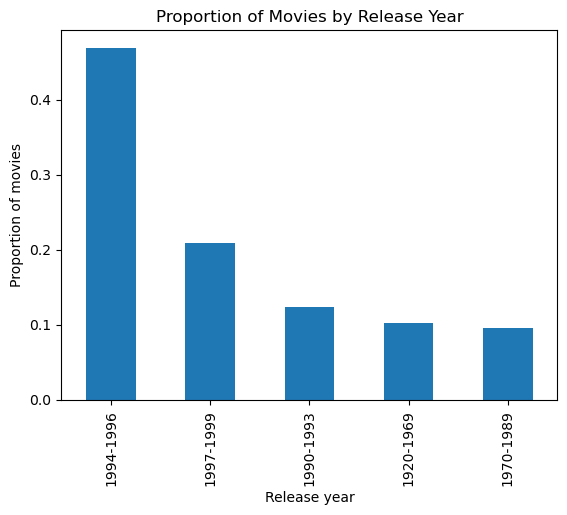

In [13]:
proportion_of_movies_by_release_year.plot(kind="bar")
plt.title("Proportion of Movies by Release Year")
plt.ylabel("Proportion of movies")
plt.xlabel("Release year")
plt.show()

Almost half the movies in the data were released in 1994-1996. Around 21% in 1997-1999. The other 3 categories had 9-12% of the movies released.

The file u.user contains the users' personal information.

In [14]:
user_df = pd.read_csv("../data/raw/ml-100k/u.user", sep="|", header=None)
user_df.columns = ["user_id", "age", "gender", "occupation" , "zip_code"]
user_df.head()
user_df.shape
user_df.info()
user_df.describe(include="all")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 943 entries, 0 to 942
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     943 non-null    int64 
 1   age         943 non-null    int64 
 2   gender      943 non-null    object
 3   occupation  943 non-null    object
 4   zip_code    943 non-null    object
dtypes: int64(2), object(3)
memory usage: 37.0+ KB


,user_id,age,gender,occupation,zip_code
count,943.000000,943.000000,943,943,943
unique,NaN,NaN,2,21,795
top,NaN,NaN,M,student,55414
freq,NaN,NaN,670,196,9
mean,472.000000,34.051962,NaN,NaN,NaN
std,272.364951,12.192740,NaN,NaN,NaN
min,1.000000,7.000000,NaN,NaN,NaN
25%,236.500000,25.000000,NaN,NaN,NaN
50%,472.000000,31.000000,NaN,NaN,NaN
75%,707.500000,43.000000,NaN,NaN,NaN


All columns in this dataframe have values filled in.

We can add an age category column to the user_df. What should the age categories be? They can be 5-15, 15-25, 25-35, 35-45, 45-60, 60+

In [15]:
bins = [5, 15, 25, 35, 45, 60, 75]
labels = ['5-15', '15-25', '25-35', '35-45', '45-60', '60-75']
user_df["age_group"] = pd.cut(user_df["age"], bins=bins, labels=labels, include_lowest=False)
user_df.head()

,user_id,age,gender,occupation,zip_code,age_group
0,1,24,M,technician,85711,15-25
1,2,53,F,other,94043,45-60
2,3,23,M,writer,32067,15-25
3,4,24,M,technician,43537,15-25
4,5,33,F,other,15213,25-35


In [16]:
proportion_of_users_by_age_group = user_df.age_group.value_counts(normalize=True)
proportion_of_users_by_age_group

age_group
25-35    0.317073
15-25    0.270414
35-45    0.193001
45-60    0.178155
60-75    0.023330
5-15     0.018028
Name: proportion, dtype: float64

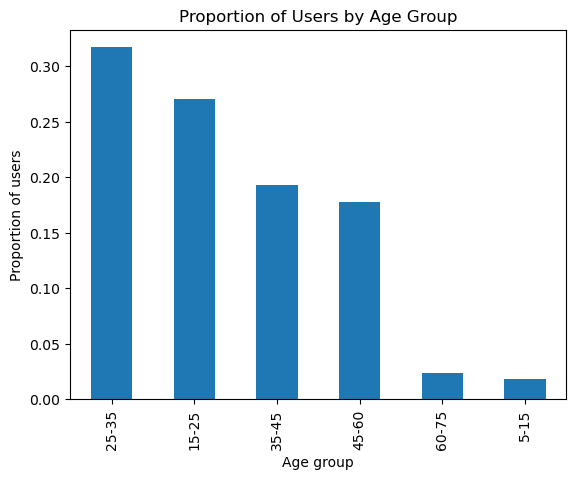

In [17]:
proportion_of_users_by_age_group.plot(kind="bar")
plt.title("Proportion of Users by Age Group")
plt.ylabel("Proportion of users")
plt.xlabel("Age group")
plt.show()

Add plot for proportion of uesers in each age group.

data_df lists all the ratings with the user_id, item_id, and timestamps. item_df has the info about the movies, with each movie having a movie_id. user_df has info about the users. Each user has a user_id. item_id in the data_df is the same as the movie_id in the item_df. One of them must be renamed for consistency. We should also check all 3 dataframes for duplicate rows and drop any duplicates.

Let us rename the item_id column in the data_df to movie_id

In [18]:
data_df.rename(columns={"item_id" : "movie_id"}, inplace=True)
data_df.head()
data_df.shape
data_df.drop_duplicates(subset=["user_id", "movie_id"]).shape
item_df.drop_duplicates(subset=["movie_id", "movie_title"]).shape

(1682, 24)

Now let us check for duplicate rows in all 3 dataframes and drop if there are any.

This confirms that no user rated a movie more than once.

In [19]:
item_df.shape

(1682, 24)

This confirms that no movie was listed more than once in item_df.

In [20]:
user_df.drop_duplicates(subset=["user_id"]).shape

(943, 6)

In [21]:
user_df.shape

(943, 6)

This confirms that no user was listed more than once in user_df.

Let us try to combine the 3 dataframes. Do we care about users who did not leave reviews? Not really. Do we care about movies that were not reviewed? Not really.

In [22]:
data_and_user_df_merge = pd.merge(data_df, user_df, on="user_id", how="left")

In [23]:
data_and_user_df_merge.shape

(100000, 9)

In [24]:
data_and_user_df_merge.head()

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,age_group
0,196,242,3,881250949,49,M,writer,55105,45-60
1,186,302,3,891717742,39,F,executive,00000,35-45
2,22,377,1,878887116,25,M,writer,40206,15-25
3,244,51,2,880606923,28,M,technician,80525,25-35
4,166,346,1,886397596,47,M,educator,55113,45-60


In [25]:
data_and_user_df_merge.isnull().sum()

user_id       0
movie_id      0
rating        0
timestamp     0
age           0
gender        0
occupation    0
zip_code      0
age_group     0
dtype: int64

The newly created dataframe seems not to have any missing values.

In [26]:
missing_rows = data_and_user_df_merge[data_and_user_df_merge.isnull().any(axis=1)]

In [27]:
missing_rows.user_id.value_counts()

Series([], Name: count, dtype: int64)

Okay, so the user with user_id 1 is the only one whose demographic info we do not have. Let us confirm by opening the file u.user. Checked the file. There are 943 users. So I made a mistake while loading the file. So we add header=None in the read_csv() function to fix things.

In [28]:
item_df.movie_id.nunique()

1682

In [29]:
data_and_user_df_merge.movie_id.nunique()

1682

In [30]:
data_df.user_id.nunique()

943

In [31]:
all_merged = pd.merge(data_and_user_df_merge, item_df, on="movie_id", how="left")

In [32]:
item_df.head(2)

,movie_id,movie_title,release_date,IMDb_URL,unknown,Action,Adventure,Animation,Childrens,Comedy,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,1,Toy Story (1995),01-Jan-1995,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1994-1996
1,2,GoldenEye (1995),01-Jan-1995,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,0,...,0,0,0,0,0,0,1,0,0,1994-1996


In [33]:
all_merged.columns

Index(['user_id', 'movie_id', 'rating', 'timestamp', 'age', 'gender',
       'occupation', 'zip_code', 'age_group', 'movie_title', 'release_date',
       'IMDb_URL', 'unknown', 'Action', 'Adventure', 'Animation', 'Childrens',
       'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir',
       'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War',
       'Western', 'release_year'],
      dtype='object')

In [34]:
all_merged.isnull().sum()

user_id          0
movie_id         0
rating           0
timestamp        0
age              0
gender           0
occupation       0
zip_code         0
age_group        0
movie_title      0
release_date     9
IMDb_URL        13
unknown          0
Action           0
Adventure        0
Animation        0
Childrens        0
Comedy           0
Crime            0
Documentary      0
Drama            0
Fantasy          0
Film-Noir        0
Horror           0
Musical          0
Mystery          0
Romance          0
Sci-Fi           0
Thriller         0
War              0
Western          0
release_year     0
dtype: int64

The newly merged df has 13 URLs missing. URLs are string. Let us replace the missing URLs with the string "No IMDb URL available"

all_merged also has 9 release dates missing. We fill those in with 30-Jun-1995. 1995 was chosen because it is the median release year.

d["Gender"].fillna('No Gender', inplace = True) 
d[10:25]

In [35]:
all_merged["IMDb_URL"] = all_merged.IMDb_URL.fillna("No IMDb URL available")
all_merged["release_date"] = all_merged.release_date.fillna("30-Jun-1995")

In [36]:
all_merged.isna().sum()

user_id         0
movie_id        0
rating          0
timestamp       0
age             0
gender          0
occupation      0
zip_code        0
age_group       0
movie_title     0
release_date    0
IMDb_URL        0
unknown         0
Action          0
Adventure       0
Animation       0
Childrens       0
Comedy          0
Crime           0
Documentary     0
Drama           0
Fantasy         0
Film-Noir       0
Horror          0
Musical         0
Mystery         0
Romance         0
Sci-Fi          0
Thriller        0
War             0
Western         0
release_year    0
dtype: int64

We now have no missing values in the all_merged dataframe.

Let us go one df at a time. We can analyze the data_df first. See how many reviews are 5 star, how many are 4 star, etc. And categorize reviews by timing.

Then we can go for the user_df. Get the proportion of users by gender, age group, profession.

We can categorize movies by genre, and review time.

In [37]:
data_df.head()
ratings_dist = data_df.rating.value_counts(normalize=True)
ratings_dist

rating
4    0.34174
3    0.27145
5    0.21201
2    0.11370
1    0.06110
Name: proportion, dtype: float64

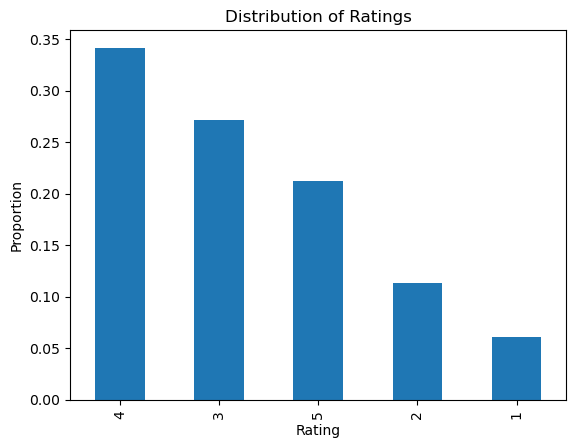

In [38]:
ratings_dist.plot(kind="bar")
plt.title("Distribution of Ratings")
plt.ylabel("Proportion")
plt.xlabel("Rating")
plt.show()

In [39]:
user_df.head()

,user_id,age,gender,occupation,zip_code,age_group
0,1,24,M,technician,85711,15-25
1,2,53,F,other,94043,45-60
2,3,23,M,writer,32067,15-25
3,4,24,M,technician,43537,15-25
4,5,33,F,other,15213,25-35


In [40]:
proportion_of_users_by_gender = user_df.gender.value_counts(normalize=True)
proportion_of_users_by_gender

gender
M    0.710498
F    0.289502
Name: proportion, dtype: float64

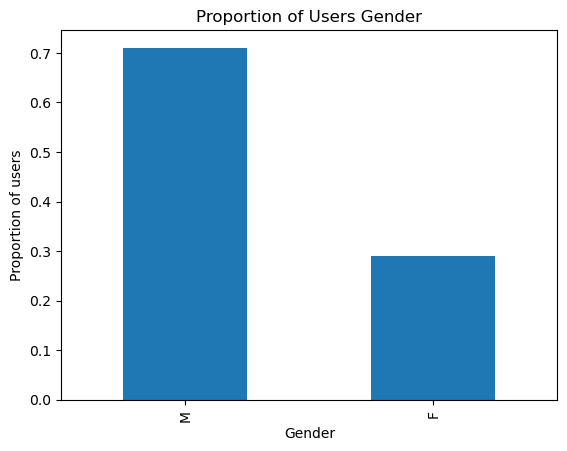

In [41]:
proportion_of_users_by_gender.plot(kind="bar")
plt.title("Proportion of Users Gender")
plt.ylabel("Proportion of users")
plt.xlabel("Gender")
plt.show()

In [42]:
proportion_of_users_by_occupation = user_df.occupation.value_counts(normalize=True).sort_values(ascending=True)
proportion_of_users_by_occupation

occupation
doctor           0.007423
homemaker        0.007423
none             0.009544
salesman         0.012725
lawyer           0.012725
retired          0.014846
healthcare       0.016967
entertainment    0.019088
marketing        0.027572
technician       0.028632
artist           0.029692
scientist        0.032874
executive        0.033934
writer           0.047720
librarian        0.054083
programmer       0.069989
engineer         0.071050
administrator    0.083775
educator         0.100742
other            0.111347
student          0.207847
Name: proportion, dtype: float64

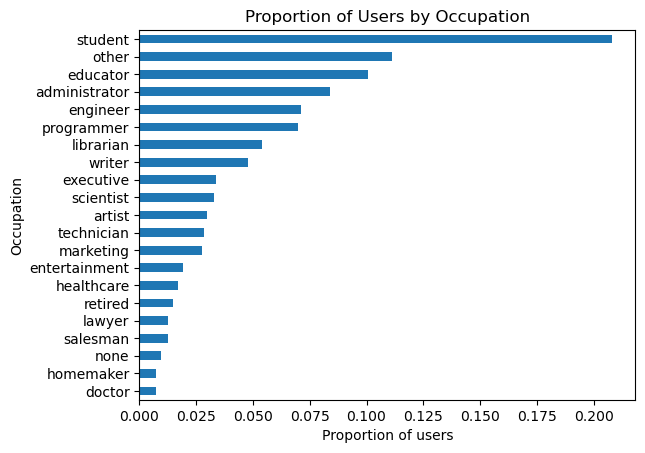

In [43]:
proportion_of_users_by_occupation.plot(kind="barh")
plt.title("Proportion of Users by Occupation")
plt.xlabel("Proportion of users")
plt.ylabel("Occupation")
plt.show()

In [44]:
proportion_of_users_by_age_group = user_df.age_group.value_counts(normalize=True)

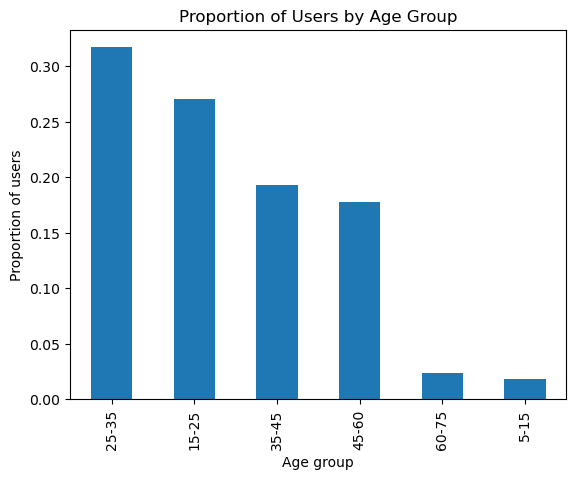

In [45]:
proportion_of_users_by_age_group.plot(kind="bar")
plt.title("Proportion of Users by Age Group")
plt.xlabel("Age group")
plt.ylabel("Proportion of users")
plt.show()

In [46]:
item_df.describe()

,movie_id,unknown,Action,Adventure,Animation,Childrens,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
count,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.00000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000,1682.000000
mean,841.500000,0.001189,0.149227,0.080262,0.024970,0.072533,0.300238,0.064804,0.029727,0.431034,0.01308,0.014269,0.054697,0.033294,0.036266,0.146849,0.060048,0.149227,0.042212,0.016052
std,485.695893,0.034473,0.356418,0.271779,0.156081,0.259445,0.458498,0.246253,0.169882,0.495368,0.11365,0.118632,0.227455,0.179456,0.187008,0.354061,0.237646,0.356418,0.201131,0.125714
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,421.250000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,841.500000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,1261.750000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,1682.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [47]:
item_df.loc[ : , "unknown" : "Western"].mean().sort_values(ascending=False)

Drama          0.431034
Comedy         0.300238
Action         0.149227
Thriller       0.149227
Romance        0.146849
Adventure      0.080262
Childrens      0.072533
Crime          0.064804
Sci-Fi         0.060048
Horror         0.054697
War            0.042212
Mystery        0.036266
Musical        0.033294
Documentary    0.029727
Animation      0.024970
Western        0.016052
Film-Noir      0.014269
Fantasy        0.013080
unknown        0.001189
dtype: float64

The above cell gives us the percentage of movies that fall in a category.

In [48]:
proportion_of_movies_by_release_year = all_merged.release_year.value_counts(normalize=True)

In [49]:
proportion_of_movies_by_release_year

release_year
1994-1996    0.39109
1997-1999    0.18384
1970-1989    0.18364
1990-1993    0.12961
1920-1969    0.11182
Name: proportion, dtype: float64

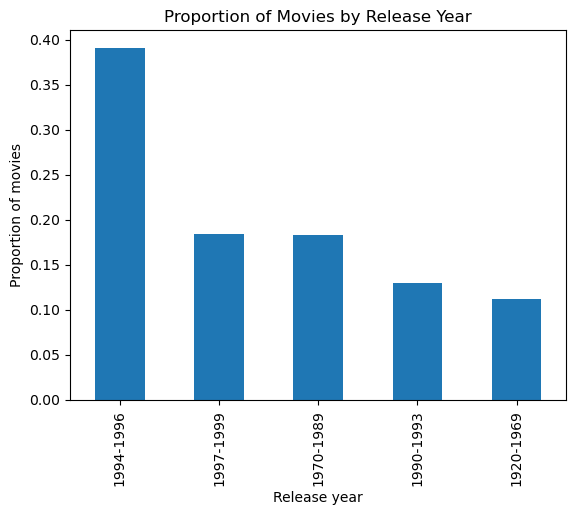

In [50]:
proportion_of_movies_by_release_year.plot(kind="bar")
plt.title("Proportion of Movies by Release Year")
plt.ylabel("Proportion of movies")
plt.xlabel("Release year")
plt.show()

Add plot for percentage of movies by release year.

Let us take a moment to think what big questions we will be answering in our analysis.



1. Which are the highest rated movies?

2. Do user demographics have any effect on movie ratings?

3. Does the release year affect rating?

4. Does the movie genre affect rating?

Let us attempt to answer #2 first

Let us see if occupation affects ratings.

In [51]:
all_merged.groupby(["occupation"])["rating"].mean().sort_values(ascending=False)

occupation
none             3.779134
lawyer           3.735316
doctor           3.688889
educator         3.670621
artist           3.653380
administrator    3.635646
scientist        3.611273
salesman         3.582944
programmer       3.568260
librarian        3.560781
other            3.552377
engineer         3.541407
technician       3.532230
student          3.515143
marketing        3.485641
retired          3.466750
entertainment    3.441050
writer           3.375723
executive        3.349104
homemaker        3.301003
healthcare       2.896220
Name: rating, dtype: float64

Add plot for average ratings by occupation. Horizontal bar.

People with occupation not listed, lawyers, doctors and educators rated films the highest on average.

Executives, homemakers, and people working in healthcare rated films the lowest on average.

Now let us see if gender affects average ratings.

In [52]:
all_merged.groupby(["gender"])["rating"].mean().sort_values(ascending=False)

gender
F    3.531507
M    3.529289
Name: rating, dtype: float64

Add plot for average ratings by gender.

Females tend to rate films very slightly higher. But there is not much of a difference.

Now let us see if age group affects average ratings.

In [53]:
average_rating_by_age_group = all_merged.groupby(["age_group"])["rating"].mean().sort_values(ascending=False)

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\2076008986.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_rating_by_age_group = all_merged.groupby(["age_group"])["rating"].mean().sort_values(ascending=False)


In [54]:
average_rating_by_age_group

age_group
45-60    3.630522
60-75    3.629232
35-45    3.575259
25-35    3.497959
15-25    3.487494
5-15     3.382049
Name: rating, dtype: float64

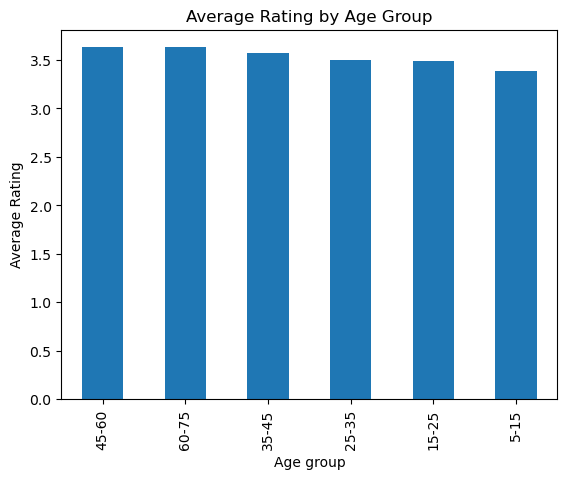

In [55]:
average_rating_by_age_group.plot(kind="bar")
plt.title("Average Rating by Age Group")
plt.ylabel("Average Rating")
plt.xlabel("Age group")
plt.show()

People in the 45-75 age range rated films the highest. We can see that younger users rated films lower than the older users. Users in the 5-15 age group rated films the lowest. Though it is worth noting that very few users belong to this age group (around 1.3% of users). 35-45 year olds rated films nearly 0.075 points higher than 25-35 year olds.

Now we attempt to find out if release year affects ratings

In [56]:
average_rating_by_release_year = all_merged.groupby(["release_year"])["rating"].mean().sort_values(ascending=False)
average_rating_by_release_year

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\39103536.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  average_rating_by_release_year = all_merged.groupby(["release_year"])["rating"].mean().sort_values(ascending=False)


release_year
1920-1969    3.929082
1970-1989    3.789316
1990-1993    3.557673
1997-1999    3.372443
1994-1996    3.358664
Name: rating, dtype: float64

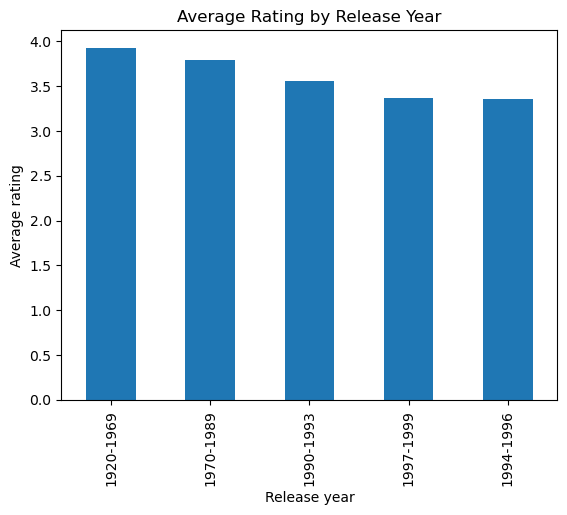

In [57]:
average_rating_by_release_year.plot(kind="bar")
plt.title("Average Rating by Release Year")
plt.ylabel("Average rating")
plt.xlabel("Release year")
plt.show()

We can see that films released in earlier years have higer average ratings than films released later.

In [58]:
all_merged.groupby(["release_year"])["rating"].count().sort_values(ascending=False)

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\1978409312.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  all_merged.groupby(["release_year"])["rating"].count().sort_values(ascending=False)


release_year
1994-1996    39109
1997-1999    18384
1970-1989    18364
1990-1993    12961
1920-1969    11182
Name: rating, dtype: int64

This might be statistically significant. Because the number of films released in all intervals defined by us is comparable.

Let us now look for the higest rated movies. We take into consideration both the number of ratings for a movie and the average rating. This is to ensure that a film with a high rating and very few reviews does not get out-ranked by a film with a slightly lower rating and many more reviews. We can consider a threshold for the minimum number of ratings we want. We can then not consider films with fewer reviews than this threshold.

In [59]:
data_df.head(3)
data_df.groupby(["movie_id"])["rating"].count().sort_values(ascending=False)
data_df.groupby(["movie_id"])["rating"].count().describe()
data_df.groupby(["movie_id"])["rating"].count().quantile([0.05, 0.20, 0.40, 0.60, 0.80])

0.05      1.0
0.20      5.0
0.40     16.0
0.60     43.0
0.80    100.0
Name: rating, dtype: float64

I have a hypothesis that the number of ratings is a proxy for popularity. To test this hypothesis, we can calculate the average rating for films with many ratings vs films with fewer ratings. If it so happens that the films with many ratings have significantly higher average ratings, we consider only films with many ratings when wanting to get the names of the most popular movies.

In [60]:
data_df.groupby(["movie_id"]).filter(lambda y: len(y) > 80).groupby(["movie_id"])["rating"].count().describe()
data_df.groupby(["movie_id"]).filter(lambda y: len(y) > 80)["rating"].mean()
data_df.groupby(["movie_id"]).filter(lambda y: len(y) <= 80).groupby(["movie_id"])["rating"].count().describe()
data_df.groupby(["movie_id"]).filter(lambda y: len(y) <= 80)["rating"].mean()
data_df.groupby(["movie_id"]).filter(lambda y: len(y) <= 80).nunique()

user_id        935
movie_id      1266
rating           5
timestamp    20402
dtype: int64

It is indeed that case that films with more number of ratings have higer average ratings for a threshold of 80 films. I think it is reasonable to set the threshold at the 75th percentile (80 reviews).

Let us get the names of top ranked films with at least 80 reviews

In [61]:
all_merged.groupby(["movie_id"]).filter(lambda y: len(y) > 80).groupby(["movie_id"])["rating"].mean().sort_values(ascending=False)

movie_id
408    4.491071
318    4.466443
169    4.466102
483    4.456790
64     4.445230
         ...   
831    2.461538
243    2.439394
412    2.397849
122    2.339623
988    2.313953
Name: rating, Length: 416, dtype: float64

Okay, we have the movie_id s of these films. The question is, how do we get titles?

In [62]:
all_merged.columns

Index(['user_id', 'movie_id', 'rating', 'timestamp', 'age', 'gender',
       'occupation', 'zip_code', 'age_group', 'movie_title', 'release_date',
       'IMDb_URL', 'unknown', 'Action', 'Adventure', 'Animation', 'Childrens',
       'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir',
       'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War',
       'Western', 'release_year'],
      dtype='object')

df.groupby('category').agg({
    'sales': 'sum',
    'price': 'mean',
    'quantity': 'max',
    'rating': 'std'
})

result = df.groupby('category').agg(
    total_sales=('sales', 'sum'),
    avg_price=('price', 'mean')
).sort_values('total_sales', ascending=False)

These are our top 10 movies:

In [63]:
top_10 = all_merged.groupby(["movie_id"]).filter(lambda y: len(y) > 80).groupby(["movie_id"]).agg(movie_title=("movie_title" , "first"), avg_rating=("rating" , "mean"), release_year=("release_year" , "first")).sort_values("avg_rating", ascending=False).head(10)
top_10
top_10.release_year.value_counts().sort_values(ascending=False)

release_year
1920-1969    4
1994-1996    3
1990-1993    2
1970-1989    1
1997-1999    0
Name: count, dtype: int64

4/10 films in the top 10 were released between 1920-1969. This might have something to do with the fact that older users rate movies higher than younger users on average.

And the next question is, how to get the average rating by genre?

In [64]:
all_merged.head(3)

,user_id,movie_id,rating,timestamp,age,gender,occupation,zip_code,age_group,movie_title,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,196,242,3,881250949,49,M,writer,55105,45-60,Kolya (1996),...,0,0,0,0,0,0,0,0,0,1997-1999
1,186,302,3,891717742,39,F,executive,00000,35-45,L.A. Confidential (1997),...,1,0,0,1,0,0,1,0,0,1997-1999
2,22,377,1,878887116,25,M,writer,40206,15-25,Heavyweights (1994),...,0,0,0,0,0,0,0,0,0,1994-1996


In [65]:
all_merged.loc[all_merged["Horror"] == 1].rating.mean()

np.float64(3.2903893172841827)

 Now, let us write a function that will do this for all genre columns.

In [66]:
def comp_avg_rating(genre_name : str):
    return float(all_merged.loc[all_merged[genre_name] == 1].rating.mean())

cols = df.loc[:, 'col1':'col7'].columns.tolist()

In [67]:
item_df.head(1)

,movie_id,movie_title,release_date,IMDb_URL,unknown,Action,Adventure,Animation,Childrens,Comedy,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,1,Toy Story (1995),01-Jan-1995,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1994-1996


In [68]:
genre_column_names = item_df.loc[:, "unknown" : "Western"].columns.to_list()
genre_column_names

['unknown',
 'Action',
 'Adventure',
 'Animation',
 'Childrens',
 'Comedy',
 'Crime',
 'Documentary',
 'Drama',
 'Fantasy',
 'Film-Noir',
 'Horror',
 'Musical',
 'Mystery',
 'Romance',
 'Sci-Fi',
 'Thriller',
 'War',
 'Western']

In [69]:
genre_ratings_dict = {}
for column_name in genre_column_names:
    genre_ratings_dict[column_name] = comp_avg_rating(column_name)

In [70]:
genre_ratings_dict

{'unknown': 3.2,
 'Action': 3.480245417953027,
 'Adventure': 3.503526503308369,
 'Animation': 3.5766990291262135,
 'Childrens': 3.3532442216652742,
 'Comedy': 3.3940734781442745,
 'Crime': 3.6322780881440098,
 'Documentary': 3.6728232189973613,
 'Drama': 3.6873793708484772,
 'Fantasy': 3.2152366863905324,
 'Film-Noir': 3.9215233698788228,
 'Horror': 3.2903893172841827,
 'Musical': 3.521396851029471,
 'Mystery': 3.63813155386082,
 'Romance': 3.621704948358255,
 'Sci-Fi': 3.5607227022780834,
 'Thriller': 3.5090069495245064,
 'War': 3.815811874866993,
 'Western': 3.6132686084142396}

In [71]:
ratings_by_genre = pd.DataFrame.from_dict([genre_ratings_dict])
ratings_by_genre
ratings_by_genre = pd.DataFrame.from_dict(genre_ratings_dict, orient='index', columns=['avg_rating']).sort_values(by="avg_rating", ascending=True)
ratings_by_genre

,avg_rating
unknown,3.200000
Fantasy,3.215237
Horror,3.290389
Childrens,3.353244
Comedy,3.394073
Action,3.480245
Adventure,3.503527
Thriller,3.509007
Musical,3.521397
Sci-Fi,3.560723


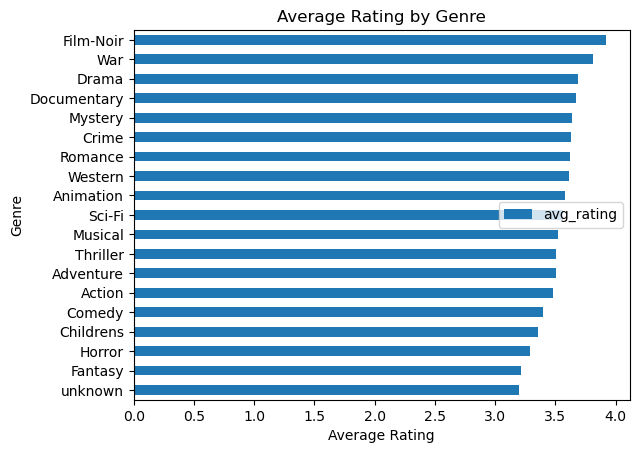

In [72]:
ratings_by_genre.plot(kind="barh")
plt.title("Average Rating by Genre")
plt.ylabel("Genre")
plt.xlabel("Average Rating")
plt.show()

In [73]:
ratings_by_genre.sort_values(by="avg_rating", ascending=False)

,avg_rating
Film-Noir,3.921523
War,3.815812
Drama,3.687379
Documentary,3.672823
Mystery,3.638132
Crime,3.632278
Romance,3.621705
Western,3.613269
Animation,3.576699
Sci-Fi,3.560723


These are the genres, from most to least popular. Film-Noir, War, Drama and Documentary have among the highest ratings. Childrens', Horror, Fantasy, and films without a known genre have among the lowest ratings.

Next Steps?

We now look at intersections. What genre is the most popular among students? What genre should be marketed to people in different age groups? To women vs men?

How does release year affect popularity by age, occupation, and gender?

Are the top movies (many ratings and above average ratings) different for different dempgraphic groups?

Create boxplots for univariate analysis

We set a threshold for top movies to have more than 80 ratings. Does a person's age, occupation, and gender affect how many reviews they leave.

And also make some plots for bivariate/multivariate analysis

In [74]:
user_df.head(2)
user_df.occupation.value_counts().sort_values(ascending=False)
user_df.occupation.value_counts(normalize=True).sort_values(ascending=False)

occupation
student          0.207847
other            0.111347
educator         0.100742
administrator    0.083775
engineer         0.071050
programmer       0.069989
librarian        0.054083
writer           0.047720
executive        0.033934
scientist        0.032874
artist           0.029692
technician       0.028632
marketing        0.027572
entertainment    0.019088
healthcare       0.016967
retired          0.014846
lawyer           0.012725
salesman         0.012725
none             0.009544
homemaker        0.007423
doctor           0.007423
Name: proportion, dtype: float64

Let us write a function that takes the subset of all_merged dataframe as a group as the input and gives us the popular genres for that group.

In [75]:
def comp_avg_rating(genre_name : str):
    return float(all_merged.loc[all_merged[genre_name] == 1].rating.mean())

In [76]:
def calc_avg_rating_df(input_df):
    genre_column_names = item_df.loc[:, "unknown" : "Western"].columns.to_list()
    my_dict = {}
    for column_name in genre_column_names:
        my_dict[column_name] = float(input_df.loc[input_df[column_name] == 1].rating.mean())
    return my_dict

In [77]:
students_df = all_merged.loc[all_merged.occupation == "student"]
student_ratings_dict = calc_avg_rating_df(students_df)
student_ratings = pd.DataFrame.from_dict(student_ratings_dict, orient="index", columns=["student"])
student_ratings.sort_values(by="student", ascending=False)

,student
Film-Noir,3.832714
Documentary,3.829060
War,3.819209
Drama,3.702842
Crime,3.657407
Romance,3.650866
Animation,3.563457
Mystery,3.555005
Western,3.549020
Sci-Fi,3.531118


In [78]:
with open("../data/raw/ml-100k/u.occupation", "r") as occ_file:
    occupation_list = occ_file.read().splitlines()
occupation_list
    # .read().splitlines() 

occupation_ratings_list = []
for occupation in occupation_list:
    subset_all_merged = all_merged.loc[all_merged.occupation == occupation]
    occupation_ratings_list.append(calc_avg_rating_df(subset_all_merged))

occupation_ratings_list

[{'unknown': nan,
  'Action': 3.538751345532831,
  'Adventure': 3.5215686274509803,
  'Animation': 3.7389162561576357,
  'Childrens': 3.448051948051948,
  'Comedy': 3.4947798456650023,
  'Crime': 3.6938053097345134,
  'Documentary': 3.875,
  'Drama': 3.7960632462084543,
  'Fantasy': 3.4680851063829787,
  'Film-Noir': 3.9727891156462585,
  'Horror': 3.39386189258312,
  'Musical': 3.596045197740113,
  'Mystery': 3.7636363636363637,
  'Romance': 3.741390513320338,
  'Sci-Fi': 3.650743099787686,
  'Thriller': 3.6044585987261146,
  'War': 3.9249363867684477,
  'Western': 3.7023809523809526},
 {'unknown': nan,
  'Action': 3.539772727272727,
  'Adventure': 3.581993569131833,
  'Animation': 3.4214876033057853,
  'Childrens': 3.391089108910891,
  'Comedy': 3.521880064829822,
  'Crime': 3.6766169154228856,
  'Documentary': 4.147058823529412,
  'Drama': 3.7899686520376177,
  'Fantasy': 3.2916666666666665,
  'Film-Noir': 4.234375,
  'Horror': 3.4607843137254903,
  'Musical': 3.4140127388535033,
  

In [79]:
ratings_by_occupation_and_genre = pd.DataFrame(occupation_ratings_list, index=occupation_list).T
ratings_by_occupation_and_genre
ratings_by_occupation_and_genre.apply(lambda x : x.nlargest(5))

,administrator,artist,doctor,educator,engineer,entertainment,executive,healthcare,homemaker,lawyer,...,marketing,none,other,programmer,retired,salesman,scientist,student,technician,writer
Action,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.053726,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Animation,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,3.976744,NaN,NaN,3.628571,NaN,NaN,NaN,NaN,NaN
Crime,NaN,NaN,3.804878,NaN,3.666121,3.710145,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,3.613139,3.860759,3.813559,3.657407,NaN,NaN
Documentary,3.875000,4.147059,NaN,NaN,3.666667,3.869565,NaN,NaN,3.500000,3.900000,...,3.583333,4.000000,3.784615,NaN,NaN,4.000000,3.882353,3.829060,3.958333,3.782609
Drama,3.796063,NaN,NaN,3.811259,3.701554,NaN,NaN,NaN,3.538462,NaN,...,3.608010,3.932836,3.719294,3.755714,NaN,3.984227,3.815451,3.702842,3.694981,3.511322
Film-Noir,3.972789,4.234375,4.111111,4.064356,3.924138,3.914894,3.603448,3.100000,NaN,4.500000,...,4.100000,NaN,3.842466,3.886525,4.023256,NaN,4.025641,3.832714,4.021739,3.968000
Horror,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.866667,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Musical,NaN,NaN,NaN,NaN,NaN,NaN,3.625954,3.277778,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mystery,3.763636,NaN,3.962963,3.789474,NaN,NaN,NaN,3.121429,3.687500,3.923077,...,3.585938,NaN,NaN,NaN,3.714286,NaN,NaN,NaN,NaN,3.629851
Romance,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.525424,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Not pretty, but does the job of telling us the top 5 genres and their ratings by occupation.

Now let us get the average rating by gender across genres

In [80]:
gender_list = ["F", "M"]

gender_ratings_list = []
for gender in gender_list:
    subset_all_merged = all_merged.loc[all_merged["gender"] == gender]
    gender_ratings_list.append(calc_avg_rating_df(subset_all_merged))

gender_ratings_list

ratings_by_gender_and_genre = pd.DataFrame(gender_ratings_list, index=gender_list).T
ratings_by_gender_and_genre

,F,M
unknown,3.500000,3.125000
Action,3.484013,3.479228
Adventure,3.517988,3.499246
Animation,3.627136,3.557471
Childrens,3.426971,3.320000
Comedy,3.424021,3.382972
Crime,3.556299,3.654049
Documentary,3.614973,3.691769
Drama,3.662246,3.696957
Fantasy,3.201102,3.220425


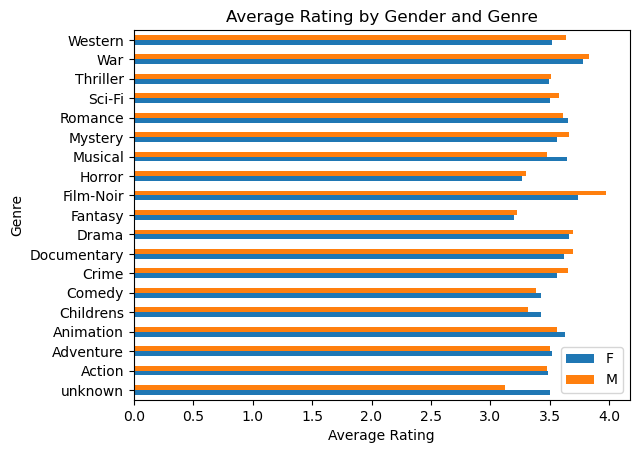

In [81]:
ratings_by_gender_and_genre.plot(kind="barh")
plt.title("Average Rating by Gender and Genre")
plt.ylabel("Genre")
plt.xlabel("Average Rating")
plt.show()

In [82]:
ratings_by_gender_and_genre.apply(lambda x : x.nlargest(5))

,F,M
Documentary,NaN,3.691769
Drama,3.662246,3.696957
Film-Noir,3.740260,3.973294
Musical,3.640083,NaN
Mystery,NaN,3.664208
Romance,3.655685,NaN
War,3.781179,3.826328


We now have the top 5 genres for females and males.

Let us now get the top 5 genres by age group.

In [83]:
age_group_list = all_merged.age_group.value_counts(normalize=True).index.to_list()
age_group_list

age_group_ratings_list = []
for age_group in age_group_list:
    subset_all_merged = all_merged.loc[all_merged["age_group"] == age_group]
    age_group_ratings_list.append(calc_avg_rating_df(subset_all_merged))

age_group_ratings_list

ratings_by_gender_and_genre = pd.DataFrame(gender_ratings_list, index=gender_list).T

ratings_by_age_group_and_genre = pd.DataFrame(age_group_ratings_list, index=age_group_list).T

ratings_by_age_group_and_genre

,25-35,15-25,35-45,45-60,5-15,60-75
unknown,2.600000,3.750000,4.000000,NaN,NaN,NaN
Action,3.440852,3.466181,3.510790,3.573040,3.507289,3.561947
Adventure,3.479418,3.471764,3.539098,3.592916,3.477833,3.589286
Animation,3.605551,3.574058,3.477021,3.642276,3.592105,3.631579
Childrens,3.382537,3.297386,3.386003,3.376879,3.211765,3.400000
Comedy,3.391663,3.336582,3.428940,3.493740,3.149533,3.475676
Crime,3.594970,3.654245,3.603125,3.692308,3.591398,3.676471
Documentary,3.679167,3.685567,3.775362,3.618497,3.000000,3.000000
Drama,3.653238,3.662493,3.724444,3.751958,3.517401,3.769352
Fantasy,3.129670,3.098131,3.343629,3.525714,2.954545,3.769231


In [84]:
ratings_by_age_group_and_genre.apply(lambda x : x.nlargest(5))

,25-35,15-25,35-45,45-60,5-15,60-75
Animation,3.605551,NaN,NaN,NaN,3.592105,NaN
Crime,NaN,NaN,NaN,NaN,3.591398,NaN
Documentary,3.679167,3.685567,3.775362,NaN,NaN,NaN
Drama,3.653238,3.662493,NaN,3.751958,NaN,3.769352
Film-Noir,3.869643,3.821809,3.985915,4.046683,NaN,3.947368
Horror,NaN,NaN,NaN,NaN,3.586207,NaN
Mystery,NaN,NaN,3.728632,3.786042,NaN,3.788732
Sci-Fi,NaN,NaN,NaN,NaN,3.647436,NaN
War,3.760632,3.800842,3.846591,3.917241,3.717391,3.784173
Western,NaN,NaN,NaN,3.865497,NaN,3.937500


Caveat: While conducting these bivariate analyses, we have not set a threshold for the minimum number of ratings like before. It is possible that some of the highly rated sub-categories have very few reviews this time.

Does release year affect popularity by age? Let us find out.

top_10 = all_merged.groupby(["movie_id"]).filter(lambda y: len(y) > 80).groupby(["movie_id"]).agg(movie_title=("movie_title" , "first"), avg_rating=("rating" , "mean"), release_year=("release_year" , "first")).sort_values("avg_rating", ascending=False).head(10)

In [85]:
avg_rating_by_age_group_and_release_year = all_merged.groupby(["age_group", "release_year"])["rating"].mean().unstack()

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\2545774261.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_rating_by_age_group_and_release_year = all_merged.groupby(["age_group", "release_year"])["rating"].mean().unstack()


Text(70.72222222222221, 0.5, 'Age group')

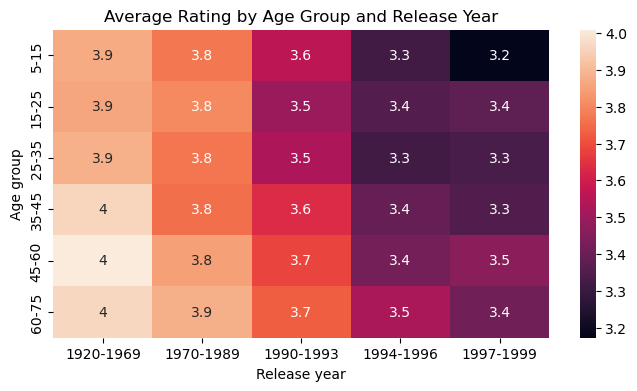

In [86]:
# Set the width and height of the figure
plt.figure(figsize=(8,4))

# Add title
plt.title("Average Rating by Age Group and Release Year")

# Heatmap showing average arrival delay for each airline by month
sns.heatmap(data=avg_rating_by_age_group_and_release_year, annot=True)

# Add label for horizontal axis
plt.xlabel("Release year")
plt.ylabel("Age group")

Even though some categories have much fewer reviews than some others, we can observe that older movies consistently have higher average ratings than newer ones across age groups.

Does release year affect popularity by gender? Let us find out.

In [87]:
avg_rating_by_gender_and_release_year = all_merged.groupby(["gender", "release_year"])["rating"].mean().unstack().unstack().unstack()
avg_rating_by_gender_and_release_year

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\1992114345.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_rating_by_gender_and_release_year = all_merged.groupby(["gender", "release_year"])["rating"].mean().unstack().unstack().unstack()


gender,F,M
release_year,,
1920-1969,3.879168,3.945669
1970-1989,3.718433,3.810575
1990-1993,3.589624,3.547116
1994-1996,3.416475,3.337678
1997-1999,3.383737,3.368132


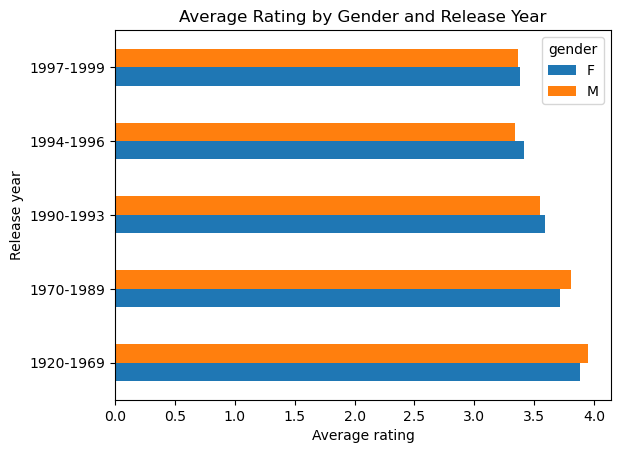

In [88]:
avg_rating_by_gender_and_release_year.plot(kind="barh")
plt.title("Average Rating by Gender and Release Year")
plt.ylabel("Release year")
plt.xlabel("Average rating")
plt.show()

In [89]:
avg_rating_by_gender_and_release_year = all_merged.groupby(["gender", "release_year"])["rating"].mean()
avg_rating_by_gender_and_release_year
all_merged.groupby(["gender", "release_year"])["rating"].count().unstack()

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\156612411.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  avg_rating_by_gender_and_release_year = all_merged.groupby(["gender", "release_year"])["rating"].mean()
C:\Users\saras\AppData\Local\Temp\ipykernel_21592\156612411.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  all_merged.groupby(["gender", "release_year"])["rating"].count().unstack()


release_year,1920-1969,1970-1989,1990-1993,1994-1996,1997-1999
gender,,,,,
F,2789,4237,3219,10416,5079
M,8393,14127,9742,28693,13305


From these numbers, we can observe that ratings vary very little by release year by gender. But men tend to rate older movies a bit higher and newer ones a bit lower compared to women.

We set a threshold for top movies to have more than 80 ratings. Does a person's age, occupation, and gender affect how many reviews they leave? Let us find out.

Does age affect number of reviews?

In [90]:
100000 / 943

106.04453870625663

On an average, each person left around 106 reviews. A unique (movie_id, user_id) pair gives us a review. So there are 100k unique pairs having (movie_id, user_id).

I don't know how to go about doing this. The question is: For each category, on an average, how many movies did a person in that category rate?

In [91]:
all_merged.groupby(["user_id"])["movie_id"].nunique().mean() # This is right
all_merged.groupby(["user_id"])["movie_id"].nunique() # This gives us the number of reviews for each user
all_merged.groupby(["age_group"])[["movie_id", "user_id"]].nunique()

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\2573040633.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  all_merged.groupby(["age_group"])[["movie_id", "user_id"]].nunique()


,movie_id,user_id
age_group,,
5-15,641,17
15-25,1523,255
25-35,1477,299
35-45,1307,182
45-60,1357,168
60-75,575,22


In [92]:
item_df.head(2
             )

,movie_id,movie_title,release_date,IMDb_URL,unknown,Action,Adventure,Animation,Childrens,Comedy,...,Film-Noir,Horror,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western,release_year
0,1,Toy Story (1995),01-Jan-1995,http://us.imdb.com/M/title-exact?Toy%20Story%2...,0,0,0,1,1,1,...,0,0,0,0,0,0,0,0,0,1994-1996
1,2,GoldenEye (1995),01-Jan-1995,http://us.imdb.com/M/title-exact?GoldenEye%20(...,0,1,1,0,0,0,...,0,0,0,0,0,0,1,0,0,1994-1996


In [93]:
data_df.head(2)

,user_id,movie_id,rating,timestamp
0,196,242,3,881250949
1,186,302,3,891717742


In [94]:
user_df.head(2)

,user_id,age,gender,occupation,zip_code,age_group
0,1,24,M,technician,85711,15-25
1,2,53,F,other,94043,45-60


In [95]:
all_merged.columns

Index(['user_id', 'movie_id', 'rating', 'timestamp', 'age', 'gender',
       'occupation', 'zip_code', 'age_group', 'movie_title', 'release_date',
       'IMDb_URL', 'unknown', 'Action', 'Adventure', 'Animation', 'Childrens',
       'Comedy', 'Crime', 'Documentary', 'Drama', 'Fantasy', 'Film-Noir',
       'Horror', 'Musical', 'Mystery', 'Romance', 'Sci-Fi', 'Thriller', 'War',
       'Western', 'release_year'],
      dtype='object')

In [96]:
# Ratings counts per age group (from cell 84)
ratings_count = all_merged['age_group'].value_counts()
# Users count per age group (from cell 219)
users_count = all_merged.groupby('age_group')['user_id'].nunique()

# Compute average ratings per user
avg_ratings_per_user = ratings_count / users_count
print(avg_ratings_per_user)

age_group
5-15      74.058824
15-25    114.921569
25-35    116.367893
35-45     94.252747
45-60     96.886905
60-75     55.045455
dtype: float64


C:\Users\saras\AppData\Local\Temp\ipykernel_21592\327070770.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  users_count = all_merged.groupby('age_group')['user_id'].nunique()


In [97]:
all_merged.age_group.value_counts()
all_merged.groupby(["age_group"])["user_id"].nunique() # number of unique users per age group
# We want: number of reviews per user for each age group
num_per_capita_ratings_by_age_group = all_merged.age_group.value_counts() / all_merged.groupby(["age_group"])["user_id"].nunique()

C:\Users\saras\AppData\Local\Temp\ipykernel_21592\2044733706.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  all_merged.groupby(["age_group"])["user_id"].nunique() # number of unique users per age group
C:\Users\saras\AppData\Local\Temp\ipykernel_21592\2044733706.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  num_per_capita_ratings_by_age_group = all_merged.age_group.value_counts() / all_merged.groupby(["age_group"])["user_id"].nunique()


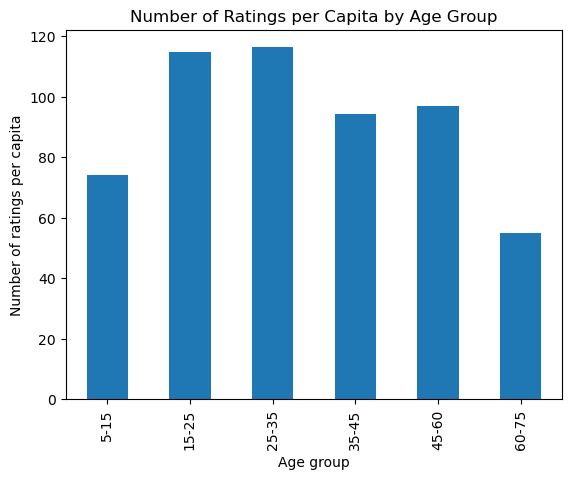

In [98]:
num_per_capita_ratings_by_age_group.plot(kind="bar")
plt.title("Number of Ratings per Capita by Age Group")
plt.ylabel("Number of ratings per capita")
plt.xlabel("Age group")
plt.show()

Users in the age range 15-35 are more active than average. Those between 35-60 are less active than average. Those between 15-15 and 60-75 are noticeably less active than average.

Does gender affect the number of per person reviews?

In [99]:
num_per_capita_ratings_by_gender = all_merged.gender.value_counts() / all_merged.groupby(["gender"])["user_id"].nunique()

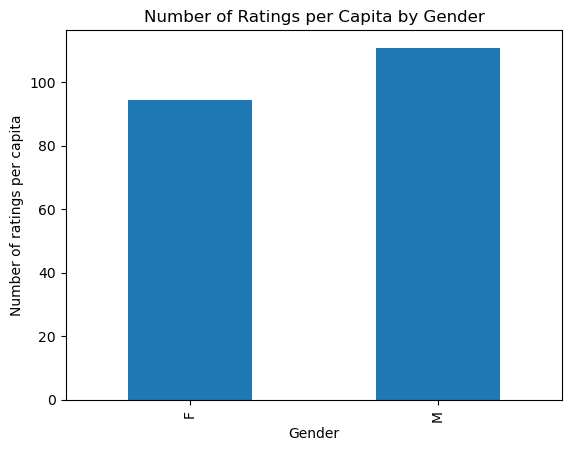

In [100]:
num_per_capita_ratings_by_gender.plot(kind="bar")
plt.title("Number of Ratings per Capita by Gender")
plt.ylabel("Number of ratings per capita")
plt.xlabel("Gender")
plt.show()

Women left fewer reviews than average, men left more reviews than average.

Now, let us see if the number of per person review left by someone depends on their occupation

In [101]:
num_ratings_by_occupation = all_merged.groupby(["occupation"]).size()
num_ratings_by_occupation
num_users_by_occupation = all_merged.groupby(["occupation"])["user_id"].nunique()
num_users_by_occupation
num_ratings_per_user_by_occupation = num_ratings_by_occupation / num_users_by_occupation
num_ratings_per_user_by_occupation.sort_values(ascending=True, inplace=True)

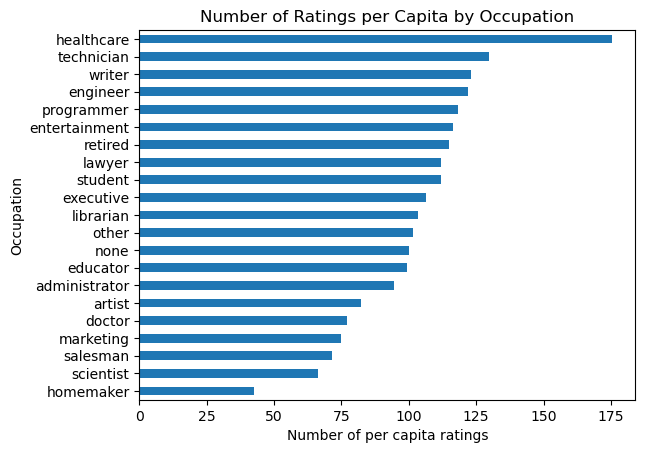

In [102]:
num_ratings_per_user_by_occupation.plot(kind="barh")
plt.title("Number of Ratings per Capita by Occupation")
plt.ylabel("Occupation")
plt.xlabel("Number of per capita ratings")
plt.show()

The number of reviews left by users varies a lot by their occupation. 

I wonder if there is a way to get the distribution of reviews left by users rather than just the mean.